# ARIMA_MODEL and SARIMAX model

### Step 1

In [2]:
# Cell 0 - imports and helper functions
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.max_open_warning": 0})


In [3]:
# Cell 1 - load data and inspect
df = pd.read_csv('Walmart.csv')
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
df = df.sort_values(['Store','Date']).reset_index(drop=True)

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Unique stores:", df['Store'].nunique())
print("Date range:", df['Date'].min().date(), "to", df['Date'].max().date())

# Show head
display(df.head())


Shape: (6435, 8)
Columns: ['Store', 'Date', 'Weekly_Sales', 'Holiday_Flag', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment']
Unique stores: 45
Date range: 2010-02-05 to 2012-10-26


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106


Correlation and pairwise plots between Weekly_Sales and other features


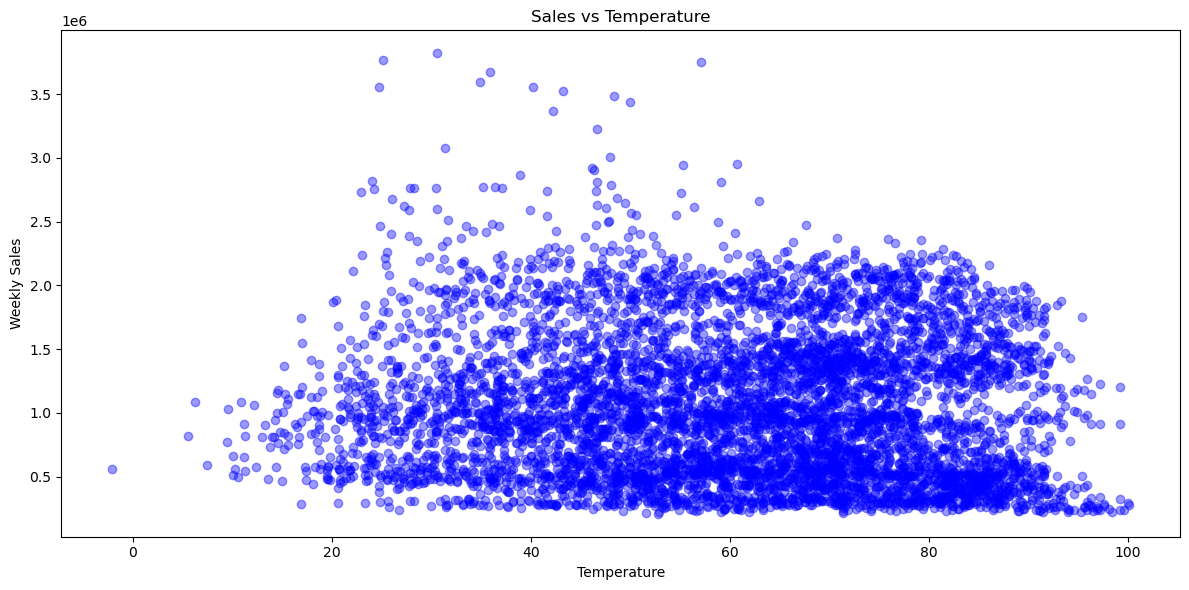

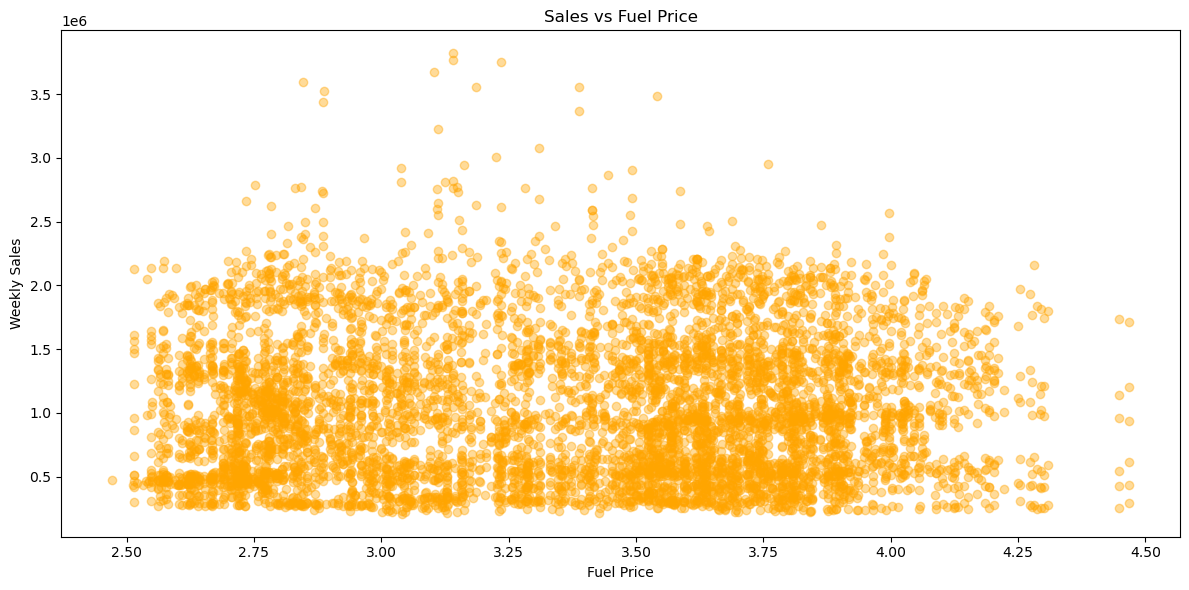

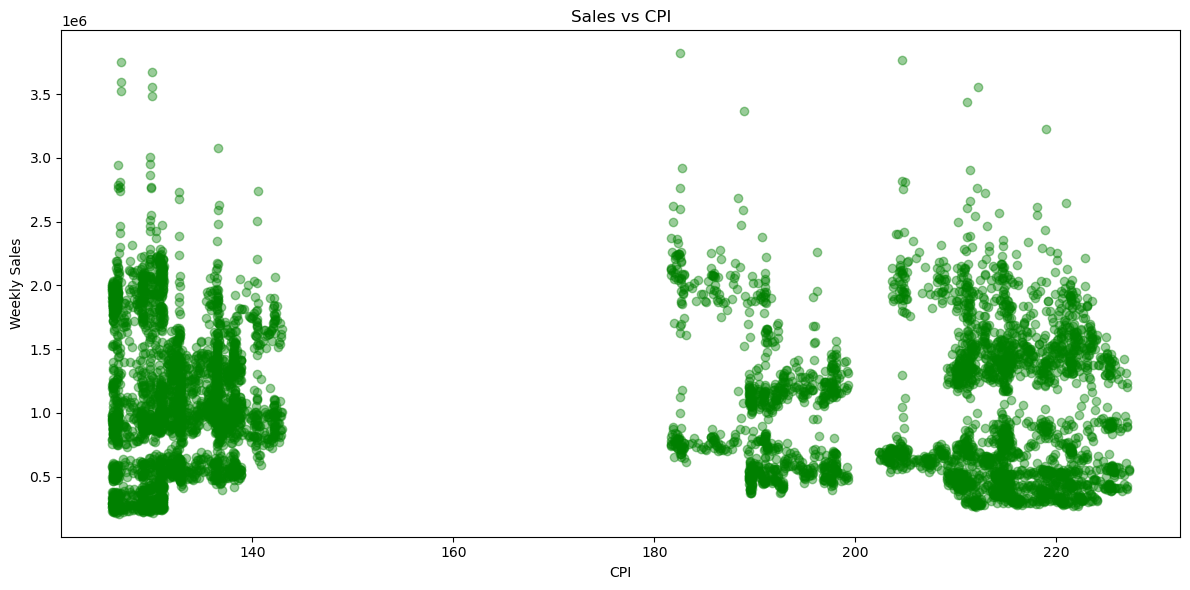

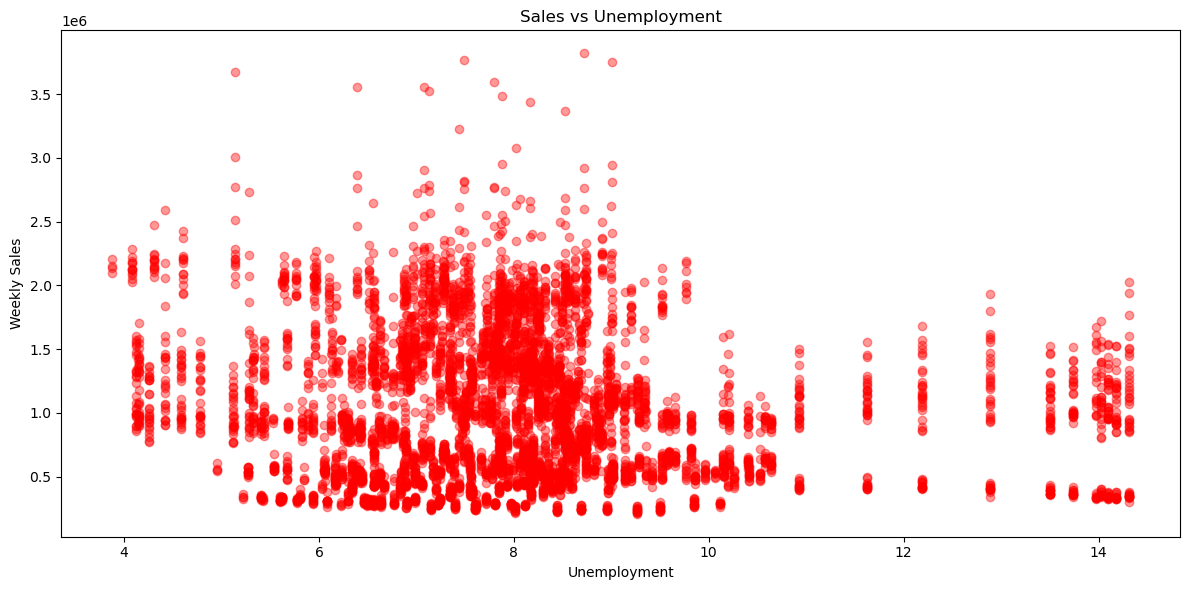

In [4]:
# Cell X - Exploratory analysis: Sales vs other variables

import seaborn as sns
import matplotlib.pyplot as plt

# Compute average weekly sales per store (to smooth a bit)
# or use full data directly depending on what you want
print("Correlation and pairwise plots between Weekly_Sales and other features")

num_cols = ['Weekly_Sales', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment']

# 1️⃣ Sales vs. Temperature
plt.figure(figsize=(12,6))
plt.scatter(df['Temperature'], df['Weekly_Sales'], alpha=0.4, color='blue')
plt.title("Sales vs Temperature")
plt.xlabel("Temperature")
plt.ylabel("Weekly Sales")
plt.tight_layout(); plt.show()

# 2️⃣ Sales vs. Fuel Price
plt.figure(figsize=(12,6))
plt.scatter(df['Fuel_Price'], df['Weekly_Sales'], alpha=0.4, color='orange')
plt.title("Sales vs Fuel Price")
plt.xlabel("Fuel Price")
plt.ylabel("Weekly Sales")
plt.tight_layout(); plt.show()

# 3️⃣ Sales vs. CPI
plt.figure(figsize=(12,6))
plt.scatter(df['CPI'], df['Weekly_Sales'], alpha=0.4, color='green')
plt.title("Sales vs CPI")
plt.xlabel("CPI")
plt.ylabel("Weekly Sales")
plt.tight_layout(); plt.show()

# 4️⃣ Sales vs. Unemployment
plt.figure(figsize=(12,6))
plt.scatter(df['Unemployment'], df['Weekly_Sales'], alpha=0.4, color='red')
plt.title("Sales vs Unemployment")
plt.xlabel("Unemployment")
plt.ylabel("Weekly Sales")
plt.tight_layout(); plt.show()


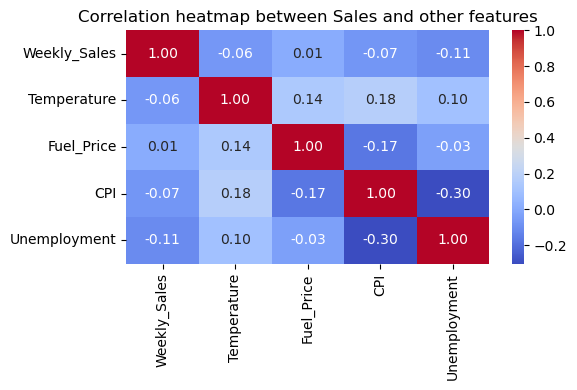

Weekly_Sales    1.000000
Fuel_Price      0.009464
Temperature    -0.063810
CPI            -0.072634
Unemployment   -0.106176
Name: Weekly_Sales, dtype: float64


In [5]:
# Cell Y - Correlation matrix heatmap
corr = df[num_cols].corr()

plt.figure(figsize=(6,4))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation heatmap between Sales and other features")
plt.tight_layout()
plt.show()

print(corr['Weekly_Sales'].sort_values(ascending=False))


In [6]:
# Cell Z - Select top correlated features for SARIMAX
corr = df[['Weekly_Sales', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment']].corr()
top_features = corr['Weekly_Sales'].drop('Weekly_Sales').abs().sort_values(ascending=False).head(2).index.tolist()

print(f"Top correlated features with Weekly_Sales: {top_features}")

# We’ll use these as exogenous variables


Top correlated features with Weekly_Sales: ['Unemployment', 'CPI']


We notice seasonality as there are spikes around Christmas and new year eve in every 52 weeks. so there is yearly seasonality, though there is no strong upward or downward trend. 

Loading data...
Selected 34 features from file:
['Holiday_Flag', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'is_major_holiday', 'is_minor_holiday', 'year', 'month', 'weekofyear', 'day_of_week', 'weekofyear_sin', 'weekofyear_cos', 'month_sin', 'month_cos', 'lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14', 'lag_28', 'lag_52', 'roll_mean_3', 'roll_mean_4', 'roll_mean_8', 'roll_mean_12', 'roll_mean_52', 'roll_std_3', 'roll_std_4', 'roll_std_8', 'roll_std_52', 'ewm_span_3', 'ewm_span_7', 'ewm_span_14']

Processing 45 stores...


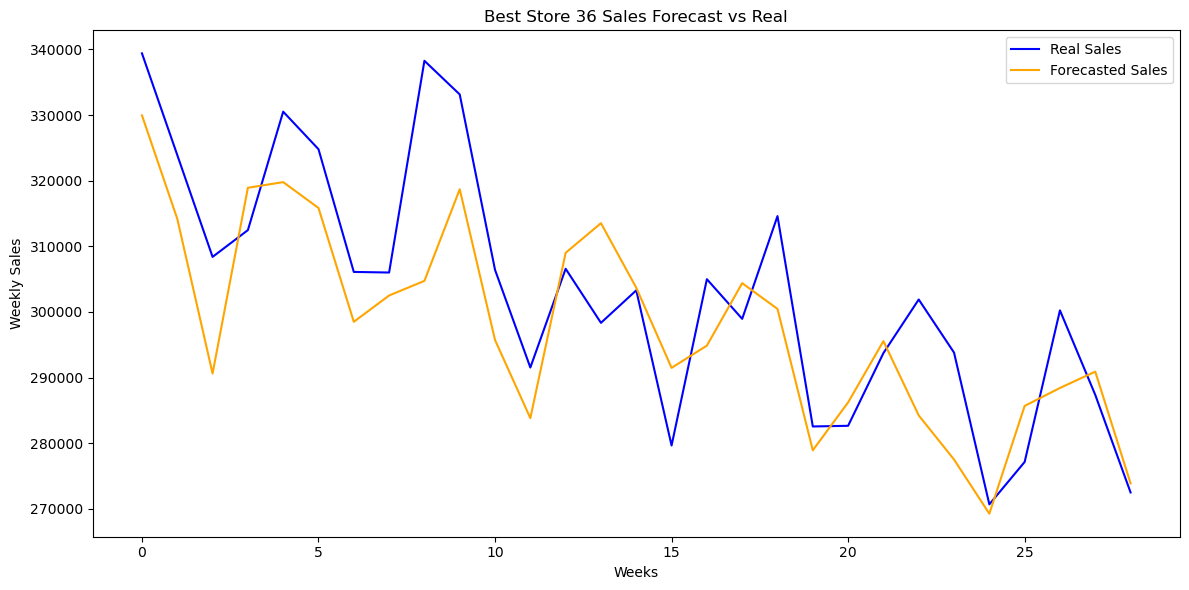

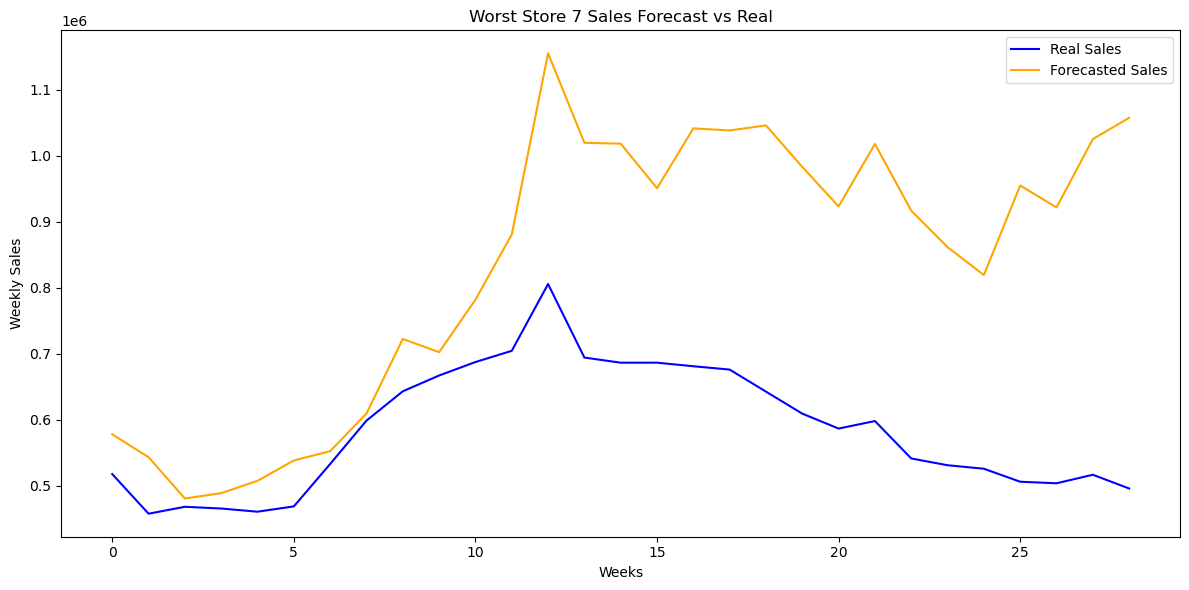


--- Final Results (Sorted by MAPE) ---
 Store ID       MAE      RMSE  MAPE (%)
       36   9305.09  11536.00      3.01
       44  12167.16  14429.08      3.60
       37  20951.84  25520.51      3.98
        4  95129.17 120315.05      4.43
        2  90134.66 121086.13      4.80
        3  22204.70  28795.15      5.32
       34  52738.50  60773.56      5.42
        8  50533.29  64797.33      5.52
        1  86938.47  99544.77      5.56
       31  93023.89 111321.04      6.79
       10 127708.42 150583.76      7.15
       26  74946.51  88730.91      7.35
       12  71576.29  92096.34      7.48
        6 116835.93 140357.56      7.49
       40  73225.73  90008.95      7.50
        5  27320.20  37480.31      8.42
       21  58480.96  75521.20      8.61
       33  25394.60  28806.69      9.46
       41 130174.31 155539.90      9.62
       28 125799.52 147426.81     10.03
       30  44078.82  45774.53     10.11
       42  60695.23  79241.93     10.87
       32 129572.36 142663.06     11.02


In [3]:
import pandas as pd
import numpy as np
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt
import warnings

# Suppress warnings for cleaner output
warnings.filterwarnings("ignore")

# --- Configuration ---
INPUT_FILE = 'features.csv'
OUTPUT_FILE = 'arima_results_filtered.csv'

def mean_absolute_percentage_error(y_true, y_pred): 
    """Calculates MAPE (Mean Absolute Percentage Error)"""
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    # Mask to avoid division by zero
    mask = y_true != 0
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

def main():
    print("Loading data...")
    try:
        df = pd.read_csv(INPUT_FILE)
    except FileNotFoundError:
        print(f"Error: {INPUT_FILE} not found.")
        return

    # 1. Data Prep
    df['Date'] = pd.to_datetime(df['Date'])
    df = df.sort_values(['Store', 'Date'])

    # 2. Dynamic Feature Selection
    # Columns to exclude (IDs, Targets, and duplicate target representations)
    exclude_cols = ['Store', 'Date', 'Weekly_Sales', 'sales_log1p']
    
    # Select all other columns present in the file as features
    exog_cols = [c for c in df.columns if c not in exclude_cols]
    
    # Double check they are numeric types
    exog_cols = [c for c in exog_cols if pd.api.types.is_numeric_dtype(df[c])]
    
    print(f"Selected {len(exog_cols)} features from file:")
    print(exog_cols)

    stores = df['Store'].unique()
    results = []
    
    print(f"\nProcessing {len(stores)} stores...")

    for store in stores:
        store_df = df[df['Store'] == store].copy()
        
        # 3. Train/Test Split (80% Train, 20% Test)
        n_rows = len(store_df)
        train_size = int(n_rows * 0.8)
        
        train = store_df.iloc[:train_size]
        test = store_df.iloc[train_size:]
        
        if len(test) == 0:
            print(f"Skipping Store {store}: Not enough data.")
            continue

        # 4. Define Target and Features
        # Use Log1p sales for training (smoother gradients)
        y_train = train['sales_log1p']
        
        # Use REAL sales for evaluation (what actually matters)
        y_test_real = test['Weekly_Sales']
        
        X_train = train[exog_cols].copy()
        X_test = test[exog_cols].copy()
        
        # 5. Handle Constant Columns (Collinearity Fix)
        # If a feature is constant in the training set (e.g. all 0s), drop it to prevent errors
        const_cols = [c for c in X_train.columns if X_train[c].nunique() <= 1]
        if const_cols:
            X_train = X_train.drop(columns=const_cols)
            X_test = X_test.drop(columns=const_cols)
            
        try:
            # 6. Train ARIMA(1,0,1)
            model = ARIMA(endog=y_train, exog=X_train, order=(1, 0, 1))
            model_fit = model.fit()
            
            # 7. Forecast
            forecast_log = model_fit.forecast(steps=len(test), exog=X_test)
            
            # Inverse Transform: Log -> Real Dollars
            forecast_real = np.expm1(forecast_log)
            
            # 8. Metrics
            mae = mean_absolute_error(y_test_real, forecast_real)
            rmse = np.sqrt(mean_squared_error(y_test_real, forecast_real))
            mape = mean_absolute_percentage_error(y_test_real, forecast_real)
            
            results.append({
                'Store ID': store,
                'MAE': round(mae, 2),
                'RMSE': round(rmse, 2),
                'MAPE (%)': round(mape, 2),
                "forecast": forecast_real.tolist(),
                "real": y_test_real.tolist()
            })
            
        except Exception as e:
            print(f"Store {store} Error: {e}")
            results.append({
                'Store ID': store,
                'MAE': np.nan,
                'RMSE': np.nan,
                'MAPE (%)': np.nan
            })

    # 9. Save and Display
    results_df = pd.DataFrame(results)
    results_df = results_df.sort_values(by='MAPE (%)', ascending=True)
    result = results_df.drop(columns=['forecast', 'real'])
    
    plt.figure(figsize=(12, 6))
    plt.plot(results_df.iloc[0]['real'], label='Real Sales', color='blue')
    plt.plot(results_df.iloc[0]['forecast'], label='Forecasted Sales', color='orange')
    plt.title(f"Best Store {results_df.iloc[0]['Store ID']} Sales Forecast vs Real")
    plt.xlabel("Weeks")
    plt.ylabel("Weekly Sales")
    plt.legend()
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(12, 6))
    plt.plot(results_df.iloc[-1]['real'], label='Real Sales', color='blue')
    plt.plot(results_df.iloc[-1]['forecast'], label='Forecasted Sales', color='orange')
    plt.title(f"Worst Store {results_df.iloc[-1]['Store ID']} Sales Forecast vs Real")
    plt.xlabel("Weeks")
    plt.ylabel("Weekly Sales")
    plt.legend()
    plt.tight_layout()
    plt.show()

    print("\n--- Final Results (Sorted by MAPE) ---")
    print(result.to_string(index=False))
    
    results_df.to_csv(OUTPUT_FILE, index=False)
    print(f"\nResults saved to {OUTPUT_FILE}")

if __name__ == "__main__":
    main()

In [8]:
import ast
import numpy as np
import pandas as pd

res_df = pd.read_csv('arima_results_filtered.csv')

def diagnostics_from_res_df(res_df, eps=1e-6):
    """Compute diagnostics using consistent assumptions:
       - NTAE = sum |pred - real| / sum(real) * 100
       - WSR = fraction of (t,store) where model abs error < persistence abs error
       - P90 MAPE, variance of per-store MAPE (percent)
       - Mean Rank across mape/mae/rmse (1=best)
    Returns a dict and prints a concise summary.
    """
    all_real_segments = []  # for overall concatenation (aligned per-store segments)
    all_pred_segments = []

    per_store_ntae = []
    per_store_wsr = []   # per-store win-rate vs persistence (in %)
    per_store_mape = []
    # keep track of wins and comparisons for overall WSR
    total_wins = 0
    total_comparisons = 0

    # iterate stores (rows)
    for idx, r in res_df.iterrows():
        # parse fields (handle stringified lists)
        reals = ast.literal_eval(r['real']) if isinstance(r['real'], str) else r['real']
        preds = ast.literal_eval(r['forecast']) if isinstance(r['forecast'], str) else r['forecast']

        real = np.asarray(reals, dtype=float)
        pred = np.asarray(preds, dtype=float)

        n = min(len(real), len(pred))
        if n == 0:
            per_store_ntae.append(np.nan)
            per_store_wsr.append(np.nan)
            per_store_mape.append(np.nan)
            continue

        # align to last n points (matching your earlier logic)
        real_a = real[-n:]
        pred_a = pred[-n:]

        # accumulate for global NTAE
        all_real_segments.append(real_a)
        all_pred_segments.append(pred_a)

        # per-store NTAE (denominator = sum(real) without abs)
        denom = real_a.sum()
        if denom == 0:
            per_store_ntae.append(np.nan)
        else:
            per_store_ntae.append(np.abs(real_a - pred_a).sum() / (denom + eps) * 100.0)

        # per-store MAPE (percent)
        per_store_mape_val = np.mean(np.abs((real_a - pred_a) / (real_a + eps))) * 100.0
        per_store_mape.append(per_store_mape_val)

        # per-store WSR vs persistence baseline (needs at least 2 points)
        if n < 2:
            per_store_wsr.append(np.nan)
        else:
            baseline = real_a[:-1]         # y_{t-1}
            target = real_a[1:]           # y_t
            preds_target = pred_a[-(n-1):]  # corresponding preds for t=1..n-1
            baseline_err = np.abs(baseline - target)
            model_err = np.abs(preds_target - target)
            wins = np.sum(model_err < baseline_err)
            comparisons = len(target)
            per_store_wsr.append(wins / comparisons * 100.0)

            total_wins += wins
            total_comparisons += comparisons

    # overall NTAE from concatenated aligned segments
    if len(all_real_segments) > 0:
        all_real = np.concatenate(all_real_segments)
        all_pred = np.concatenate(all_pred_segments)
        sum_abs_err = np.abs(all_pred - all_real).sum()
        sum_actuals = all_real.sum()  # note: NO absolute in denominator by original assumption
        overall_ntae = sum_abs_err / (sum_actuals + eps) * 100.0 if sum_actuals != 0 else np.nan
    else:
        overall_ntae = np.nan
        sum_abs_err = 0.0
        sum_actuals = 0.0

    overall_wsr = (total_wins / total_comparisons * 100.0) if total_comparisons > 0 else np.nan

    # Use existing per-store mape column if present, else use computed per_store_mape
    if 'mape' in res_df.columns and not res_df['mape'].isnull().all():
        per_store_mape_arr = res_df['mape'].values.astype(float)
    else:
        per_store_mape_arr = np.array(per_store_mape, dtype=float)

    # P90 MAPE and variance
    if per_store_mape_arr.size > 0:
        p90_mape = np.nanpercentile(per_store_mape_arr, 90)
        var_mape = np.nanvar(per_store_mape_arr)
    else:
        p90_mape = np.nan
        var_mape = np.nan

    # Prepare ranks and mean rank: prefer res_df's mape/mae/rmse if available
    rank_df = res_df.copy()
    # ensure columns exist; if not, compute approximate ones using stored per-store lists (best-effort)
    if not {'mape', 'mae', 'rmse'}.issubset(rank_df.columns):
        # compute basic MAE/RMSE/MAPE per-store from available lists
        mae_list = []
        rmse_list = []
        mape_list = []
        for idx, r in res_df.iterrows():
            reals = ast.literal_eval(r['real']) if isinstance(r['real'], str) else r['real']
            preds = ast.literal_eval(r['forecast']) if isinstance(r['forecast'], str) else r['forecast']
            real = np.asarray(reals, dtype=float)
            pred = np.asarray(preds, dtype=float)
            n = min(len(real), len(pred))
            if n == 0:
                mae_list.append(np.nan); rmse_list.append(np.nan); mape_list.append(np.nan)
            else:
                real_a = real[-n:]; pred_a = pred[-n:]
                mae_list.append(np.mean(np.abs(pred_a - real_a)))
                rmse_list.append(np.sqrt(np.mean((pred_a - real_a)**2)))
                mape_list.append(np.mean(np.abs((pred_a - real_a) / (real_a + eps))) * 100.0)
        rank_df['mae'] = mae_list
        rank_df['rmse'] = rmse_list
        rank_df['mape'] = mape_list

    # compute ranks (1 = best = smallest metric)
    ranks = rank_df[['mape', 'mae', 'rmse']].rank(method='average', ascending=True)
    rank_df['mean_rank'] = ranks.mean(axis=1)
    mean_rank_overall = rank_df['mean_rank'].mean()

    # Print concise summary
    print("Aggregate Metrics:")
    print(f"Overall NTAE (%): {overall_ntae:.6f}  ")
    print(f"Overall WSR vs persistence: {overall_wsr:.3f}% ")
    print(f"P90 MAPE (per-store) (%): {p90_mape:.2f}")
    print(f"Variance of MAPE: {var_mape:.6f}")
    
    return {
        'overall_ntae': overall_ntae,
        'overall_wsr': overall_wsr,
        'p90_mape': p90_mape,
        'var_mape': var_mape,
        'mean_rank_overall': mean_rank_overall,
        'per_store_ntae': np.array(per_store_ntae),
        'per_store_wsr': np.array(per_store_wsr),
        'per_store_mape': per_store_mape_arr,
        'rank_df': rank_df
    }

metrics = diagnostics_from_res_df(res_df)


Aggregate Metrics:
Overall NTAE (%): 13.368401  
Overall WSR vs persistence: 22.063% 
P90 MAPE (per-store) (%): 24.09
Variance of MAPE: 70.855793
